# Anomaly Detection — Magnet Power Supply
### Stage 3: LSTM-Based Predictive Anomaly Detection

This notebook is the **third stage** of the Magnet Power Supply digital-twin project.

**Pipeline recap:**
1. Stage 1 — Generated a synthetic magnet power supply dataset using a physics-based digital twin.
2. Stage 2 — Trained an LSTM model to predict `Temperature` from `Current`.
3. **Stage 3 (this notebook)** — Uses the *already-trained* LSTM model to detect anomalous operating conditions by comparing predicted vs. measured temperature.

> ⚠️ This notebook does **NOT** regenerate the dataset and does **NOT** retrain the LSTM model. It strictly loads existing artifacts:
> - `magnet_power_supply_dataset.csv`
> - `lstm_temperature_model.keras`


In [94]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


## 0. Environment Setup
Import all required libraries.

In [95]:
# ==========================================================================
# SECTION 0: ENVIRONMENT SETUP
# ==========================================================================

import numpy as np
import pandas as pd
import tensorflow as tf
from tensorflow import keras

import matplotlib.pyplot as plt
import matplotlib.ticker as mticker

from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

import os
import warnings
warnings.filterwarnings("ignore")

# Reproducibility
np.random.seed(42)
tf.random.set_seed(42)

# Plot style
plt.rcParams.update({
    "figure.figsize": (12, 5),
    "figure.dpi": 120,
    "axes.grid": True,
    "grid.alpha": 0.3,
    "font.size": 11,
    "axes.titlesize": 13,
    "axes.titleweight": "bold",
    "axes.labelsize": 11,
})

print("TensorFlow version:", tf.__version__)
print("Environment ready.")


TensorFlow version: 2.20.0
Environment ready.


In [96]:
import os

print(os.getcwd())
print(os.listdir())

/content
['.config', 'magnet_power_supply_dataset.csv', 'lstm_temperature_model.keras', '.ipynb_checkpoints', 'figure4_error_histogram.png', 'figure2_prediction_error.png', 'anomaly_detection_results.csv', 'drive', 'figure3_detected_anomalies.png', 'figure1_actual_vs_predicted_temperature.png', 'sample_data']


## 1. File Locations

If running in Google Colab and your files are stored in Google Drive, mount the drive and update `DATA_DIR` accordingly. If the dataset and model are uploaded directly to the Colab session storage, leave `DATA_DIR = "."`.

In [97]:
# ==========================================================================
# SECTION 1: FILE PATHS (edit DATA_DIR if your files live in Google Drive)
# ==========================================================================

# Uncomment the following two lines if your files are in Google Drive
from google.colab import drive
drive.mount('/content/drive')
import os

DATASET_PATH = "magnet_power_supply_dataset.csv"
MODEL_PATH = "lstm_temperature_model.keras"

print("Dataset exists:", os.path.exists(DATASET_PATH))
print("Model exists:", os.path.exists(MODEL_PATH))


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Dataset exists: True
Model exists: True


## 2. Load Dataset

In [98]:
# ==========================================================================
# SECTION 2: LOAD DATA
# ==========================================================================

df = pd.read_csv(DATASET_PATH)

print("Dataset shape:", df.shape)
print("\nColumns:", list(df.columns))
print("\nMissing values per column:")
print(df.isnull().sum())

print("\nFirst five rows:")
df.head()


Dataset shape: (50000, 10)

Columns: ['Sample', 'Time_s', 'Current_A', 'AmbientTemperature_C', 'ElectricalResistance_Ohm', 'Power_W', 'TrueTemperature_C', 'MeasuredTemperature_C', 'FaultLabel', 'FaultType']

Missing values per column:
Sample                          0
Time_s                          0
Current_A                       0
AmbientTemperature_C            0
ElectricalResistance_Ohm        0
Power_W                         0
TrueTemperature_C               0
MeasuredTemperature_C           0
FaultLabel                      0
FaultType                   50000
dtype: int64

First five rows:


,Sample,Time_s,Current_A,AmbientTemperature_C,ElectricalResistance_Ohm,Power_W,TrueTemperature_C,MeasuredTemperature_C,FaultLabel,FaultType
0,0,0.0,0.018349,24.962469,0.800000,0.000067,24.999935,25.0,0,NaN
1,1,1.0,0.039896,25.065963,0.800000,0.000678,25.000050,25.0,0,NaN
2,2,2.0,0.061317,25.062598,0.800000,0.002049,25.000159,25.0,0,NaN
3,3,3.0,0.085423,24.920191,0.800001,0.004307,25.000023,25.0,0,NaN
4,4,4.0,0.102672,24.927175,0.800000,0.007076,24.999900,25.0,0,NaN


## 3. Preprocessing

Uses the **exact same preprocessing** used during LSTM training:
- Feature: `Current_A`
- Target: `MeasuredTemperature_C` (falls back to `TrueTemperature_C` if not present)
- Normalization: `MinMaxScaler`
- Sliding windows of size **50**


In [99]:
# ==========================================================================
# SECTION 3: PREPROCESSING
# ==========================================================================

FEATURE_COL = "Current_A"

if "MeasuredTemperature_C" in df.columns:
    TARGET_COL = "MeasuredTemperature_C"
elif "TrueTemperature_C" in df.columns:
    TARGET_COL = "TrueTemperature_C"
else:
    raise ValueError("Neither 'MeasuredTemperature_C' nor 'TrueTemperature_C' found in dataset.")

print(f"Using feature column : {FEATURE_COL}")
print(f"Using target column  : {TARGET_COL}")

# Time axis (if not present, synthesize an index-based time axis)
if "Time_s" in df.columns:
    time_axis = df["Time_s"].values
else:
    time_axis = np.arange(len(df))

current_raw = df[FEATURE_COL].values.reshape(-1, 1)
temp_raw    = df[TARGET_COL].values.reshape(-1, 1)

# --- Normalization (MinMaxScaler) ---
current_scaler = MinMaxScaler()
temp_scaler    = MinMaxScaler()

current_scaled = current_scaler.fit_transform(current_raw)
temp_scaled    = temp_scaler.fit_transform(temp_raw)

# --- Sliding window creation ---
WINDOW_SIZE = 50

def create_sequences(feature_series, target_series, window_size):
    X, y = [], []
    for i in range(len(feature_series) - window_size):
        X.append(feature_series[i:i + window_size, 0])
        y.append(target_series[i + window_size, 0])
    return np.array(X), np.array(y)

X_seq, y_seq = create_sequences(current_scaled, temp_scaled, WINDOW_SIZE)

# Reshape for LSTM input: (samples, timesteps, features)
X_seq = X_seq.reshape((X_seq.shape[0], X_seq.shape[1], 1))

# Corresponding time axis / actual current for the result table (aligned with y_seq)
aligned_time    = time_axis[WINDOW_SIZE:]
aligned_current = current_raw[WINDOW_SIZE:].flatten()

print("X_seq shape:", X_seq.shape)
print("y_seq shape:", y_seq.shape)


Using feature column : Current_A
Using target column  : MeasuredTemperature_C
X_seq shape: (49950, 50, 1)
y_seq shape: (49950,)


## 4. Load Trained LSTM Model
The model is loaded as-is. **No training or fine-tuning occurs.**

In [100]:
# ==========================================================================
# SECTION 4: LOAD TRAINED MODEL (NO RETRAINING)
# ==========================================================================

model = keras.models.load_model(MODEL_PATH)
model.summary()


Model: "LSTM_Temperature_Predictor"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 50, 64)         │        16,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 50, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ (None, 32)             │        12,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 89,573 (349.90 KB)

 Trainable params: 29,857 (116.63 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 59,716 (233.27 KB)

## 5. Predict Temperature

In [101]:
# ==========================================================================
# SECTION 5: PREDICTION
# ==========================================================================

y_pred_scaled = model.predict(X_seq, verbose=0)

# Inverse transform to physical units (Celsius)
PredictedTemperature = temp_scaler.inverse_transform(y_pred_scaled.reshape(-1, 1)).flatten()
ActualTemperature     = temp_scaler.inverse_transform(y_seq.reshape(-1, 1)).flatten()

print("Prediction complete.")
print("Number of predicted samples:", len(PredictedTemperature))


Prediction complete.
Number of predicted samples: 49950


## 6. Prediction Error

In [102]:
# ==========================================================================
# SECTION 6: PREDICTION ERROR
# ==========================================================================

AbsoluteError = np.abs(ActualTemperature - PredictedTemperature)
SquaredError  = (ActualTemperature - PredictedTemperature) ** 2

print("Sample absolute errors (first 10):")
print(np.round(AbsoluteError[:10], 4))


Sample absolute errors (first 10):
[5.7947 5.8929 5.8923 5.7919 5.8918 5.7922 5.7928 5.6928 5.793  5.794 ]


## 7. Anomaly Threshold

Threshold is computed automatically using the 3-sigma rule:

**Threshold = Mean(Error) + 3 × StdDev(Error)**


In [103]:
# ==========================================================================
# SECTION 7: ANOMALY THRESHOLD (MEAN + 3*STD)
# ==========================================================================

error_mean = np.mean(AbsoluteError)
error_std  = np.std(AbsoluteError)
THRESHOLD  = error_mean + 3 * error_std


print(f"Mean Error          : {error_mean:.4f} °C")
print(f"Standard Deviation  : {error_std:.4f} °C")
print(f"Anomaly Threshold   : {THRESHOLD:.4f} °C")

import json

threshold_data = {
    "threshold": float(THRESHOLD),
    "mean_error": float(error_mean),
    "std_error": float(error_std)
}

with open("anomaly_threshold.json", "w") as f:
    json.dump(threshold_data, f, indent=4)

print("Threshold saved successfully.")

Mean Error          : 6.3469 °C
Standard Deviation  : 8.7060 °C
Anomaly Threshold   : 32.4650 °C
Threshold saved successfully.


## 8. Anomaly Detection

In [104]:
# ==========================================================================
# SECTION 8: ANOMALY DETECTION
# ==========================================================================

Anomaly = (AbsoluteError > THRESHOLD).astype(int)

total_anomalies   = int(np.sum(Anomaly))
total_normal      = int(len(Anomaly) - total_anomalies)
anomaly_percentage = 100.0 * total_anomalies / len(Anomaly)

print(f"Total samples        : {len(Anomaly)}")
print(f"Total anomalies      : {total_anomalies}")
print(f"Normal samples       : {total_normal}")
print(f"Anomaly percentage   : {anomaly_percentage:.3f}%")


Total samples        : 49950
Total anomalies      : 2465
Normal samples       : 47485
Anomaly percentage   : 4.935%


## 9. Consolidated Result Table

In [105]:
# ==========================================================================
# SECTION 9: RESULT TABLE
# ==========================================================================

results_df = pd.DataFrame({
    "Time_s": aligned_time,
    "Current_A": aligned_current,
    "ActualTemperature": ActualTemperature,
    "PredictedTemperature": PredictedTemperature,
    "PredictionError": AbsoluteError,
    "Threshold": THRESHOLD,
    "Anomaly": Anomaly
})

results_df.head(10)


,Time_s,Current_A,ActualTemperature,PredictedTemperature,PredictionError,Threshold,Anomaly
0,50.0,0.495470,25.0,30.794668,5.794668,32.464968,0
1,51.0,0.502165,24.9,30.792940,5.892940,32.464968,0
2,52.0,0.497470,24.9,30.792349,5.892349,32.464968,0
3,53.0,0.498460,25.0,30.791878,5.791878,32.464968,0
4,54.0,0.499869,24.9,30.791796,5.891796,32.464968,0
5,55.0,0.499174,25.0,30.792210,5.792210,32.464968,0
6,56.0,0.495311,25.0,30.792753,5.792753,32.464968,0
7,57.0,0.497613,25.1,30.792782,5.692782,32.464968,0
8,58.0,0.502792,25.0,30.792967,5.792967,32.464968,0
9,59.0,0.502033,25.0,30.793961,5.793961,32.464968,0


## 10. Save Results to CSV

In [106]:
# ==========================================================================
# SECTION 10: SAVE RESULTS
# ==========================================================================

RESULTS_PATH = os.path.join(DATA_DIR, "anomaly_detection_results.csv")
results_df.to_csv(RESULTS_PATH, index=False)

print(f"Results saved to: {RESULTS_PATH}")


Results saved to: ./anomaly_detection_results.csv


## 11. Visualization

Four publication-quality figures:
1. Actual vs Predicted Temperature
2. Prediction Error vs Sample Number (with threshold line)
3. Detected anomalies overlaid on the temperature curve
4. Histogram of prediction errors (with threshold marker)


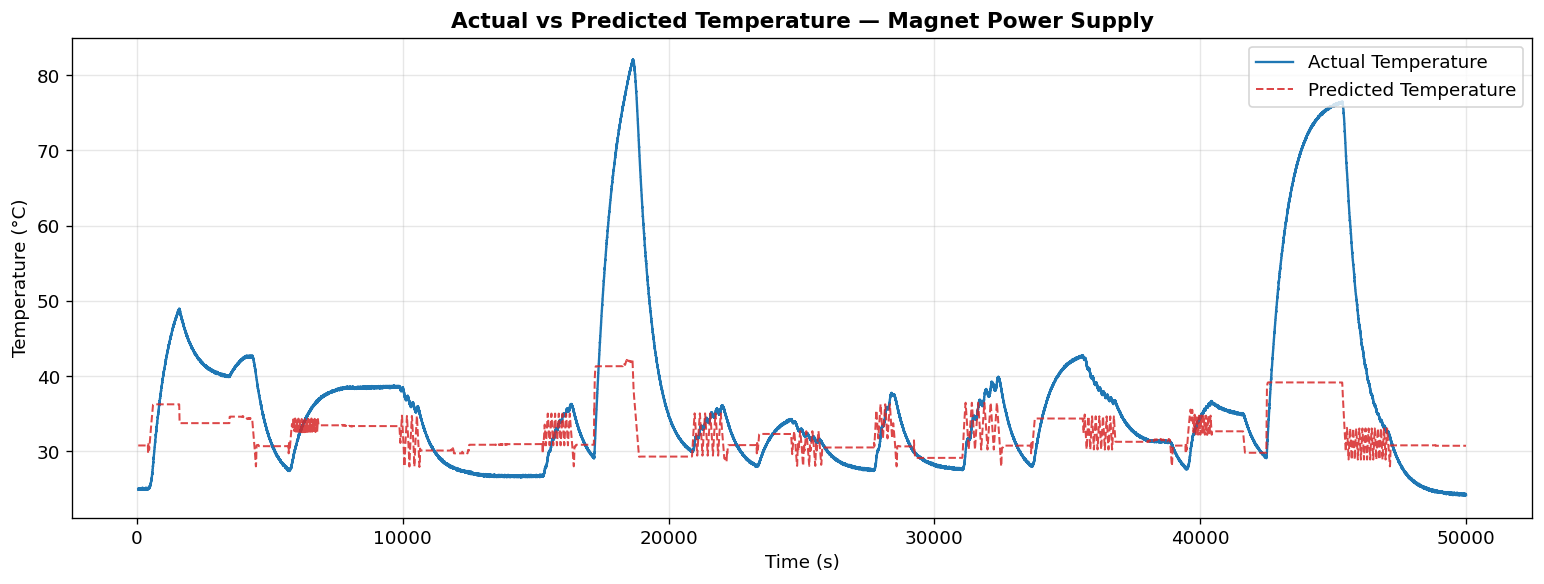

In [107]:
# ==========================================================================
# SECTION 11.1: FIGURE 1 — ACTUAL vs PREDICTED TEMPERATURE
# ==========================================================================

fig1, ax1 = plt.subplots(figsize=(13, 5))

ax1.plot(aligned_time, ActualTemperature, label="Actual Temperature", color="#1f77b4", linewidth=1.4)
ax1.plot(aligned_time, PredictedTemperature, label="Predicted Temperature", color="#d62728",
         linewidth=1.2, linestyle="--", alpha=0.85)

ax1.set_title("Actual vs Predicted Temperature — Magnet Power Supply")
ax1.set_xlabel("Time (s)")
ax1.set_ylabel("Temperature (°C)")
ax1.legend(loc="upper right")
fig1.tight_layout()
fig1.savefig("figure1_actual_vs_predicted_temperature.png", dpi=200)
plt.show()


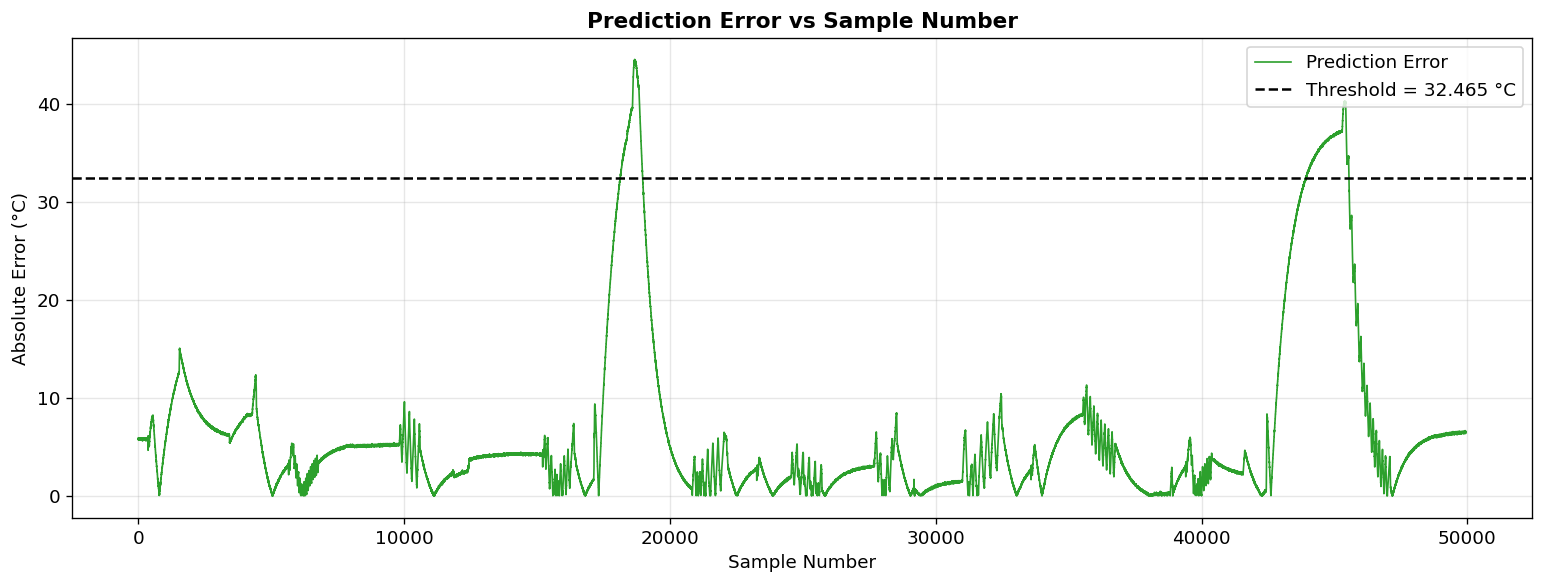

In [108]:
# ==========================================================================
# SECTION 11.2: FIGURE 2 — PREDICTION ERROR vs SAMPLE NUMBER
# ==========================================================================

fig2, ax2 = plt.subplots(figsize=(13, 5))

sample_idx = np.arange(len(AbsoluteError))
ax2.plot(sample_idx, AbsoluteError, color="#2ca02c", linewidth=1.0, label="Prediction Error")
ax2.axhline(THRESHOLD, color="black", linestyle="--", linewidth=1.5,
            label=f"Threshold = {THRESHOLD:.3f} °C")

ax2.set_title("Prediction Error vs Sample Number")
ax2.set_xlabel("Sample Number")
ax2.set_ylabel("Absolute Error (°C)")
ax2.legend(loc="upper right")
fig2.tight_layout()
fig2.savefig("figure2_prediction_error.png", dpi=200)
plt.show()


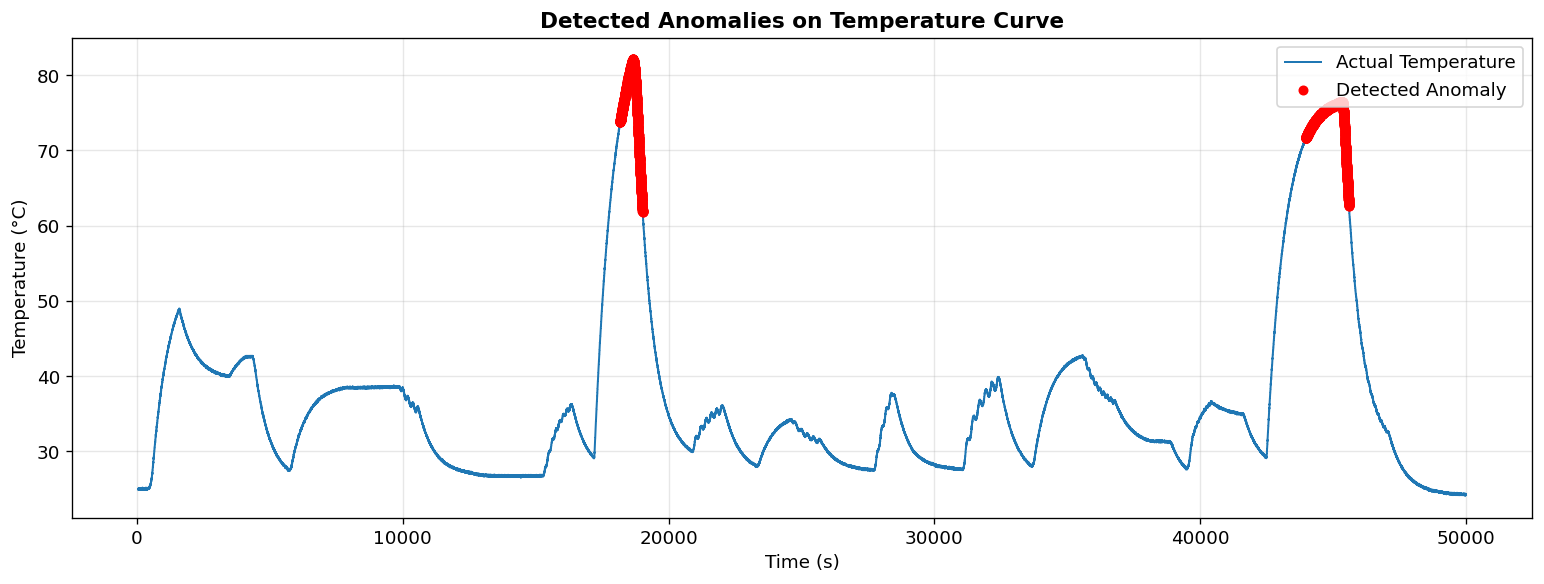

In [109]:
# ==========================================================================
# SECTION 11.3: FIGURE 3 — DETECTED ANOMALIES ON TEMPERATURE CURVE
# ==========================================================================

fig3, ax3 = plt.subplots(figsize=(13, 5))

ax3.plot(aligned_time, ActualTemperature, label="Actual Temperature", color="#1f77b4", linewidth=1.2)

anomaly_mask = Anomaly == 1
ax3.scatter(aligned_time[anomaly_mask], ActualTemperature[anomaly_mask],
            color="red", s=25, zorder=5, label="Detected Anomaly")

ax3.set_title("Detected Anomalies on Temperature Curve")
ax3.set_xlabel("Time (s)")
ax3.set_ylabel("Temperature (°C)")
ax3.legend(loc="upper right")
fig3.tight_layout()
fig3.savefig("figure3_detected_anomalies.png", dpi=200)
plt.show()


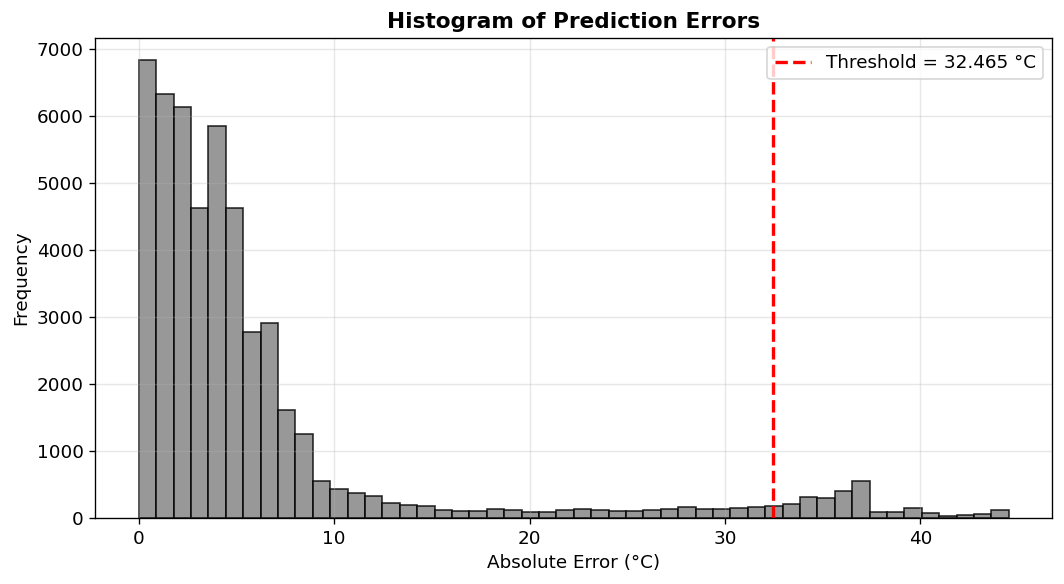

In [110]:
# ==========================================================================
# SECTION 11.4: FIGURE 4 — HISTOGRAM OF PREDICTION ERRORS
# ==========================================================================

fig4, ax4 = plt.subplots(figsize=(9, 5))

ax4.hist(AbsoluteError, bins=50, color="#7f7f7f", edgecolor="black", alpha=0.8)
ax4.axvline(THRESHOLD, color="red", linestyle="--", linewidth=2,
            label=f"Threshold = {THRESHOLD:.3f} °C")

ax4.set_title("Histogram of Prediction Errors")
ax4.set_xlabel("Absolute Error (°C)")
ax4.set_ylabel("Frequency")
ax4.legend(loc="upper right")
fig4.tight_layout()
fig4.savefig("figure4_error_histogram.png", dpi=200)
plt.show()


## 12. Evaluation Metrics

In [111]:
# ==========================================================================
# SECTION 12: EVALUATION METRICS
# ==========================================================================

max_error = np.max(AbsoluteError)
min_error = np.min(AbsoluteError)
avg_error = np.mean(AbsoluteError)

rmse = np.sqrt(mean_squared_error(ActualTemperature, PredictedTemperature))
mae  = mean_absolute_error(ActualTemperature, PredictedTemperature)
r2   = r2_score(ActualTemperature, PredictedTemperature)

print(f"Maximum Error       : {max_error:.4f} °C")
print(f"Minimum Error       : {min_error:.4f} °C")
print(f"Average Error       : {avg_error:.4f} °C")
print(f"RMSE                : {rmse:.4f} °C")
print(f"MAE                 : {mae:.4f} °C")
print(f"R\u00b2 Score            : {r2:.4f}")
print(f"Number of Anomalies : {total_anomalies}")


Maximum Error       : 44.5371 °C
Minimum Error       : 0.0000 °C
Average Error       : 6.3469 °C
RMSE                : 10.7739 °C
MAE                 : 6.3469 °C
R² Score            : 0.1711
Number of Anomalies : 2465


## 13. Engineering Summary

## 14. Output Files Generated

In [112]:
# ==========================================================================
# SECTION 14: OUTPUT FILES SUMMARY
# ==========================================================================

output_files = [
    "anomaly_detection_results.csv",
    "figure1_actual_vs_predicted_temperature.png",
    "figure2_prediction_error.png",
    "figure3_detected_anomalies.png",
    "figure4_error_histogram.png",
    "engineering_summary.txt",
]

print("Generated output files:")
for f in output_files:
    exists = os.path.exists(os.path.join(DATA_DIR, f))
    status = "OK" if exists else "MISSING"
    print(f" - {f:45s} [{status}]")


Generated output files:
 - anomaly_detection_results.csv                 [OK]
 - figure1_actual_vs_predicted_temperature.png   [OK]
 - figure2_prediction_error.png                  [OK]
 - figure3_detected_anomalies.png                [OK]
 - figure4_error_histogram.png                   [OK]
 - engineering_summary.txt                       [MISSING]
